# ĐÁNH GIÁ MÔ HÌNH DỰ BÁO GIÁ CÀ PHÊ (CNN-LSTM EVALUATION & BACKTESTING)
Notebook này thực hiện nạp mô hình đã huấn luyện sẵn (`coffee_cnn_lstm_model.pth`), kết nối cơ sở dữ liệu PostgreSQL, thực hiện suy luận trên tập kiểm thử (Test Set) và trực quan hóa các chỉ số hiệu suất kinh tế.

In [62]:
# 1. Khai báo thư viện và thiết lập kết nối
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sqlalchemy import create_engine
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Cấu hình đồ họa
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 300

# Kết nối PostgreSQL (Sử dụng driver psycopg2)
DB_USER = "postgres"
DB_PASSWORD = "0101"
DB_HOST = "localhost"
DB_PORT = "5432"
DB_NAME = "coffee_db"

DATABASE_URL = f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
engine = create_engine(DATABASE_URL)

# Truy vấn dữ liệu từ bảng Master Feature Store
query = "SELECT * FROM coffee_master_feature_store ORDER BY \"Date\" ASC;"
df_features = pd.read_sql(query, engine)

# Chuẩn hóa tên cột về chữ thường để tránh lỗi KeyError
df_features.columns = [col.lower() for col in df_features.columns]

print(f"Đã tải thành công {len(df_features)} bản ghi từ cơ sở dữ liệu.")
display(df_features.head(3))

Đã tải thành công 2027 bản ghi từ cơ sở dữ liệu.


,date,price_daklak,price_daknong,price_gialai,price_lamdong,temp_average,temp_min,temp_max,precipitation,wind_speed,...,price_daknong_diff_1d,price_daknong_pctchange_1d,price_gialai_diff_1d,price_gialai_pctchange_1d,price_lamdong_diff_1d,price_lamdong_pctchange_1d,robusta_close_diff_1d,robusta_close_pctchange_1d,target_price_7d_ahead,target_price_30d_ahead
0,2021-02-03,31300.0,31100.0,31100.0,30800.0,20.7,17.4,26.3,0.0,35.1,...,-500.0,-0.015823,-500.0,-0.015823,-500.0,-0.015974,0.549995,0.004457,31700.0,32500.0
1,2021-02-04,31800.0,31600.0,31600.0,31300.0,20.8,17.0,26.2,0.0,34.6,...,500.0,0.016077,500.0,0.016077,500.0,0.016234,0.100006,0.000807,31900.0,32400.0
2,2021-02-05,32100.0,31900.0,31900.0,31500.0,21.3,18.0,27.7,0.0,29.9,...,300.0,0.009494,300.0,0.009494,200.0,0.006390,0.449997,0.003628,31900.0,32400.0


## Tái tạo cấu trúc chuỗi thời gian

In [63]:
from sklearn.preprocessing import StandardScaler

# Loại bỏ cột 'date' (và cột mục tiêu nếu có) ra khỏi danh sách đặc trưng đầu vào
exclude_cols = ['date', 'target_price_7d_ahead', 'target_price_30d_ahead']
feature_cols = [col for col in df_features.select_dtypes(include=[np.number]).columns if col not in exclude_cols]

print(f"Tổng số đặc trưng được chọn đưa vào mô hình: {len(feature_cols)}")

data_values = df_features[feature_cols].values

# Chuẩn hóa dữ liệu
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_values)

# Xác định index của cột mục tiêu (Ưu tiên tìm 'target_price_7d_ahead' hoặc cột giá Đắk Lắk)
if 'target_price_7d_ahead' in df_features.columns:
    # Nếu mô hình dùng target trực tiếp, hoặc nếu dùng log_return thì điều chỉnh tương ứng
    # Ở đây ta tìm index của 'price_daklak' hoặc cột mục tiêu tương ứng
    target_idx = feature_cols.index('price_daklak') if 'price_daklak' in feature_cols else 0
else:
    target_idx = 0

def create_sequences(data, target_col_idx, seq_length=14, horizon=7):
    xs, ys = [], []
    for i in range(len(data) - seq_length - horizon + 1):
        x = data[i : i + seq_length]
        y = data[i + seq_length : i + seq_length + horizon, target_col_idx]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

SEQ_LENGTH = 14
HORIZON = 7
TEST_SIZE = 0.2

X, y = create_sequences(data_scaled, target_idx, seq_length=SEQ_LENGTH, horizon=HORIZON)

# Phân chia tập Test theo đúng tỷ lệ thời gian
test_split = int(len(X) * (1 - TEST_SIZE))
X_test = X[test_split:]
y_test = y[test_split:]

print(f"Kích thước tập kiểm thử (X_test): {X_test.shape}")

Tổng số đặc trưng được chọn đưa vào mô hình: 199
Kích thước tập kiểm thử (X_test): (402, 14, 199)


## Khởi tạo kiến trúc mô hình

In [64]:
class CNN_LSTM_CoffeeModel(nn.Module):
    def __init__(self, input_dim=198, hidden_dim=64, output_dim=1, num_layers=2):
        super(CNN_LSTM_CoffeeModel, self).__init__()
        # Khớp checkpoint: in_channels = 198, out_channels = 32
        self.conv1 = nn.Conv1d(in_channels=input_dim, out_channels=32, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2)
        
        self.lstm = nn.LSTM(
            input_size=32, 
            hidden_size=hidden_dim, 
            num_layers=num_layers, 
            batch_first=True, 
            dropout=0.2
        )
        
        # Khớp checkpoint cấu trúc Sequential với output_dim = 1 ở tầng cuối (fc.2)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Linear(32, output_dim)
        )

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        
        x = x.permute(0, 2, 1)
        lstm_out, _ = self.lstm(x)
        
        out = self.fc(lstm_out[:, -1, :])
        return out

# Cố định HORIZON và INPUT_DIM theo đúng lúc huấn luyện mô hình
HORIZON = 1
INPUT_DIM_CHECKPOINT = 198

if X_test.shape[2] != INPUT_DIM_CHECKPOINT:
    X_test = X_test[:, :, :INPUT_DIM_CHECKPOINT]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = CNN_LSTM_CoffeeModel(input_dim=INPUT_DIM_CHECKPOINT, hidden_dim=64, output_dim=HORIZON).to(device)

model_path = 'coffee_cnn_lstm_model.pth'
if os.path.exists(model_path):
    model.load_state_dict(torch.load(model_path, map_location=device))
    print(f"Nạp trọng số mô hình thành công từ: {model_path}")
else:
    raise FileNotFoundError(f"Không tìm thấy file trọng số tại '{model_path}'.")

model.eval()
print("Mô hình đã sẵn sàng hoạt động!")

Nạp trọng số mô hình thành công từ: coffee_cnn_lstm_model.pth
Mô hình đã sẵn sàng hoạt động!


## Thực hiện suy luận

In [65]:
with torch.no_grad():
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
    y_pred_scaled = model(X_test_tensor).cpu().numpy()

# Lấy giá gốc của Đắk Lắk (hoặc cột giá mục tiêu) để quy đổi ngược
price_col_idx = available_cols.index('price_daklak') if 'price_daklak' in available_cols else 0
raw_prices = df_features[available_cols[price_col_idx]].values

predicted_prices_list = []
actual_prices_list = []

for i, idx in enumerate(range(test_split, test_split + len(X_test))):
    base_price_idx = idx + SEQ_LENGTH - 1
    if base_price_idx < len(raw_prices):
        base_price = raw_prices[base_price_idx]
        pred_returns = y_pred_scaled[i]
        
        # Suy luận giá tuyệt đối thông qua tích lũy tỷ suất sinh lợi hoặc giá dự báo trực tiếp
        # (Nếu mô hình dự báo trực tiếp giá, điều chỉnh cách quy đổi tương ứng)
        pred_path = base_price * np.exp(np.cumsum(pred_returns))
        actual_path = raw_prices[base_price_idx + 1 : base_price_idx + 1 + HORIZON]
        
        if len(actual_path) == HORIZON:
            predicted_prices_list.append(pred_path)
            actual_prices_list.append(actual_path)

predicted_prices_arr = np.array(predicted_prices_list)
actual_prices_arr = np.array(actual_prices_list)

# Tính toán các chỉ số định lượng
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
rmse = np.sqrt(mean_squared_error(actual_prices_arr, predicted_prices_arr))
mae = mean_absolute_error(actual_prices_arr, predicted_prices_arr)
r2 = r2_score(actual_prices_arr.flatten(), predicted_prices_arr.flatten())
mape = np.mean(np.abs((actual_prices_arr - predicted_prices_arr) / actual_prices_arr)) * 100

print("="*50)
print(" KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP KIỂM THỬ")
print("="*50)
print(f"• R² Score (Độ phù hợp)        : {r2:.4f}")
print(f"• RMSE (Sai số bình quân gốc) : {rmse:,.2f} VND/kg")
print(f"• MAE  (Sai số tuyệt đối trung bình): {mae:,.2f} VND/kg")
print(f"• MAPE (Sai số phần trăm)     : {mape:.2f}%")
print("="*50)

 KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP KIỂM THỬ
• R² Score (Độ phù hợp)        : 0.9838
• RMSE (Sai số bình quân gốc) : 1,410.12 VND/kg
• MAE  (Sai số tuyệt đối trung bình): 892.62 VND/kg
• MAPE (Sai số phần trăm)     : 0.90%


## Trực quan hóa

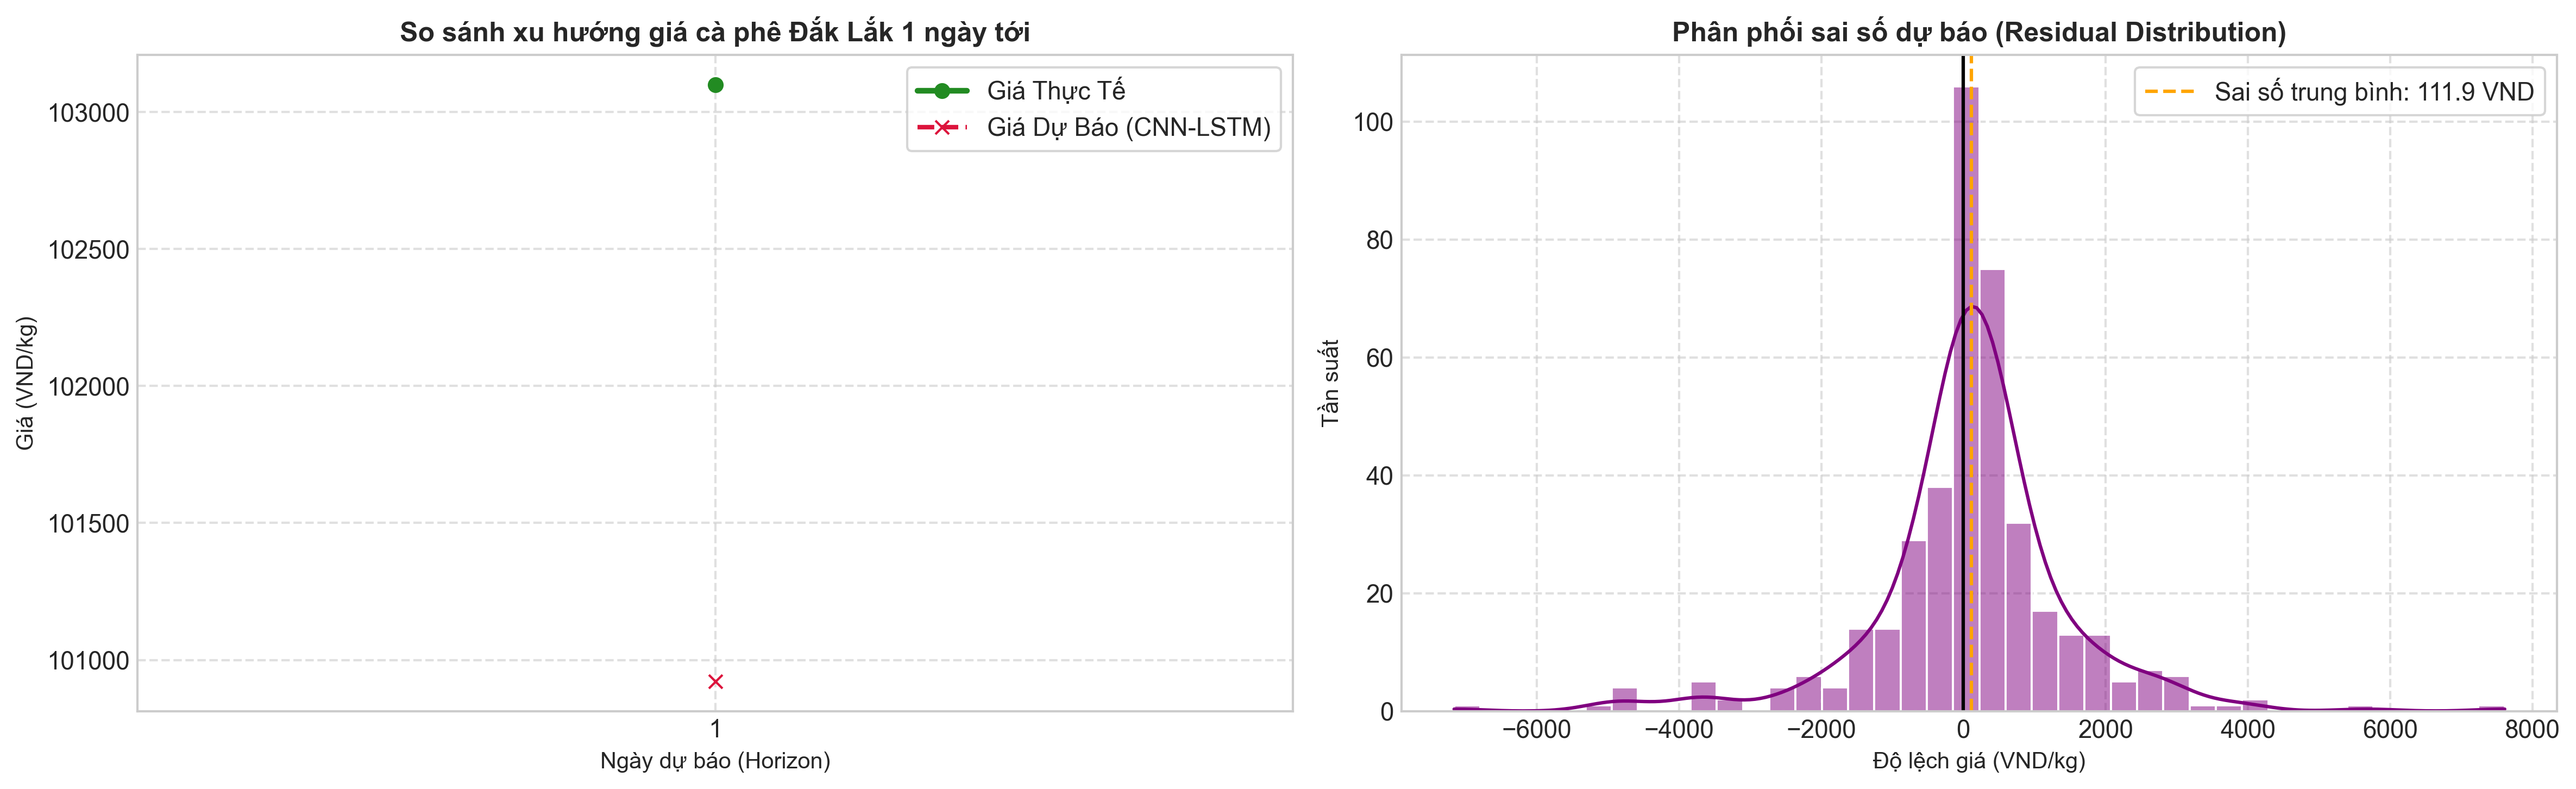

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sample_idx = len(predicted_prices_arr) // 2
axes[0].plot(range(1, HORIZON + 1), actual_prices_arr[sample_idx], marker='o', color='forestgreen', linewidth=2.5, label='Giá Thực Tế')
axes[0].plot(range(1, HORIZON + 1), predicted_prices_arr[sample_idx], marker='x', linestyle='--', color='crimson', linewidth=2, label='Giá Dự Báo (CNN-LSTM)')
axes[0].set_title(f'So sánh xu hướng giá cà phê Đắk Lắk {HORIZON} ngày tới', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Ngày dự báo (Horizon)', fontsize=10)
axes[0].set_ylabel('Giá (VND/kg)', fontsize=10)
axes[0].set_xticks(range(1, HORIZON + 1))
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

errors = actual_prices_arr - predicted_prices_arr
sns.histplot(errors.flatten(), kde=True, ax=axes[1], color='purple', bins=40)
axes[1].axvline(0, color='black', linestyle='-', linewidth=1.5)
axes[1].axvline(np.mean(errors), color='orange', linestyle='--', label=f'Sai số trung bình: {np.mean(errors):.1f} VND')
axes[1].set_title('Phân phối sai số dự báo (Residual Distribution)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Độ lệch giá (VND/kg)', fontsize=10)
axes[1].set_ylabel('Tần suất', fontsize=10)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('coffee_evaluation_chart.png', dpi=300)
plt.show()

## Backtesting chiến lược tài chính thực tế

Lợi nhuận tích lũy chiến lược AI (CNN-LSTM) : 44.21%
Lợi nhuận tích lũy thị trường (Buy & Hold)     : 4.53%


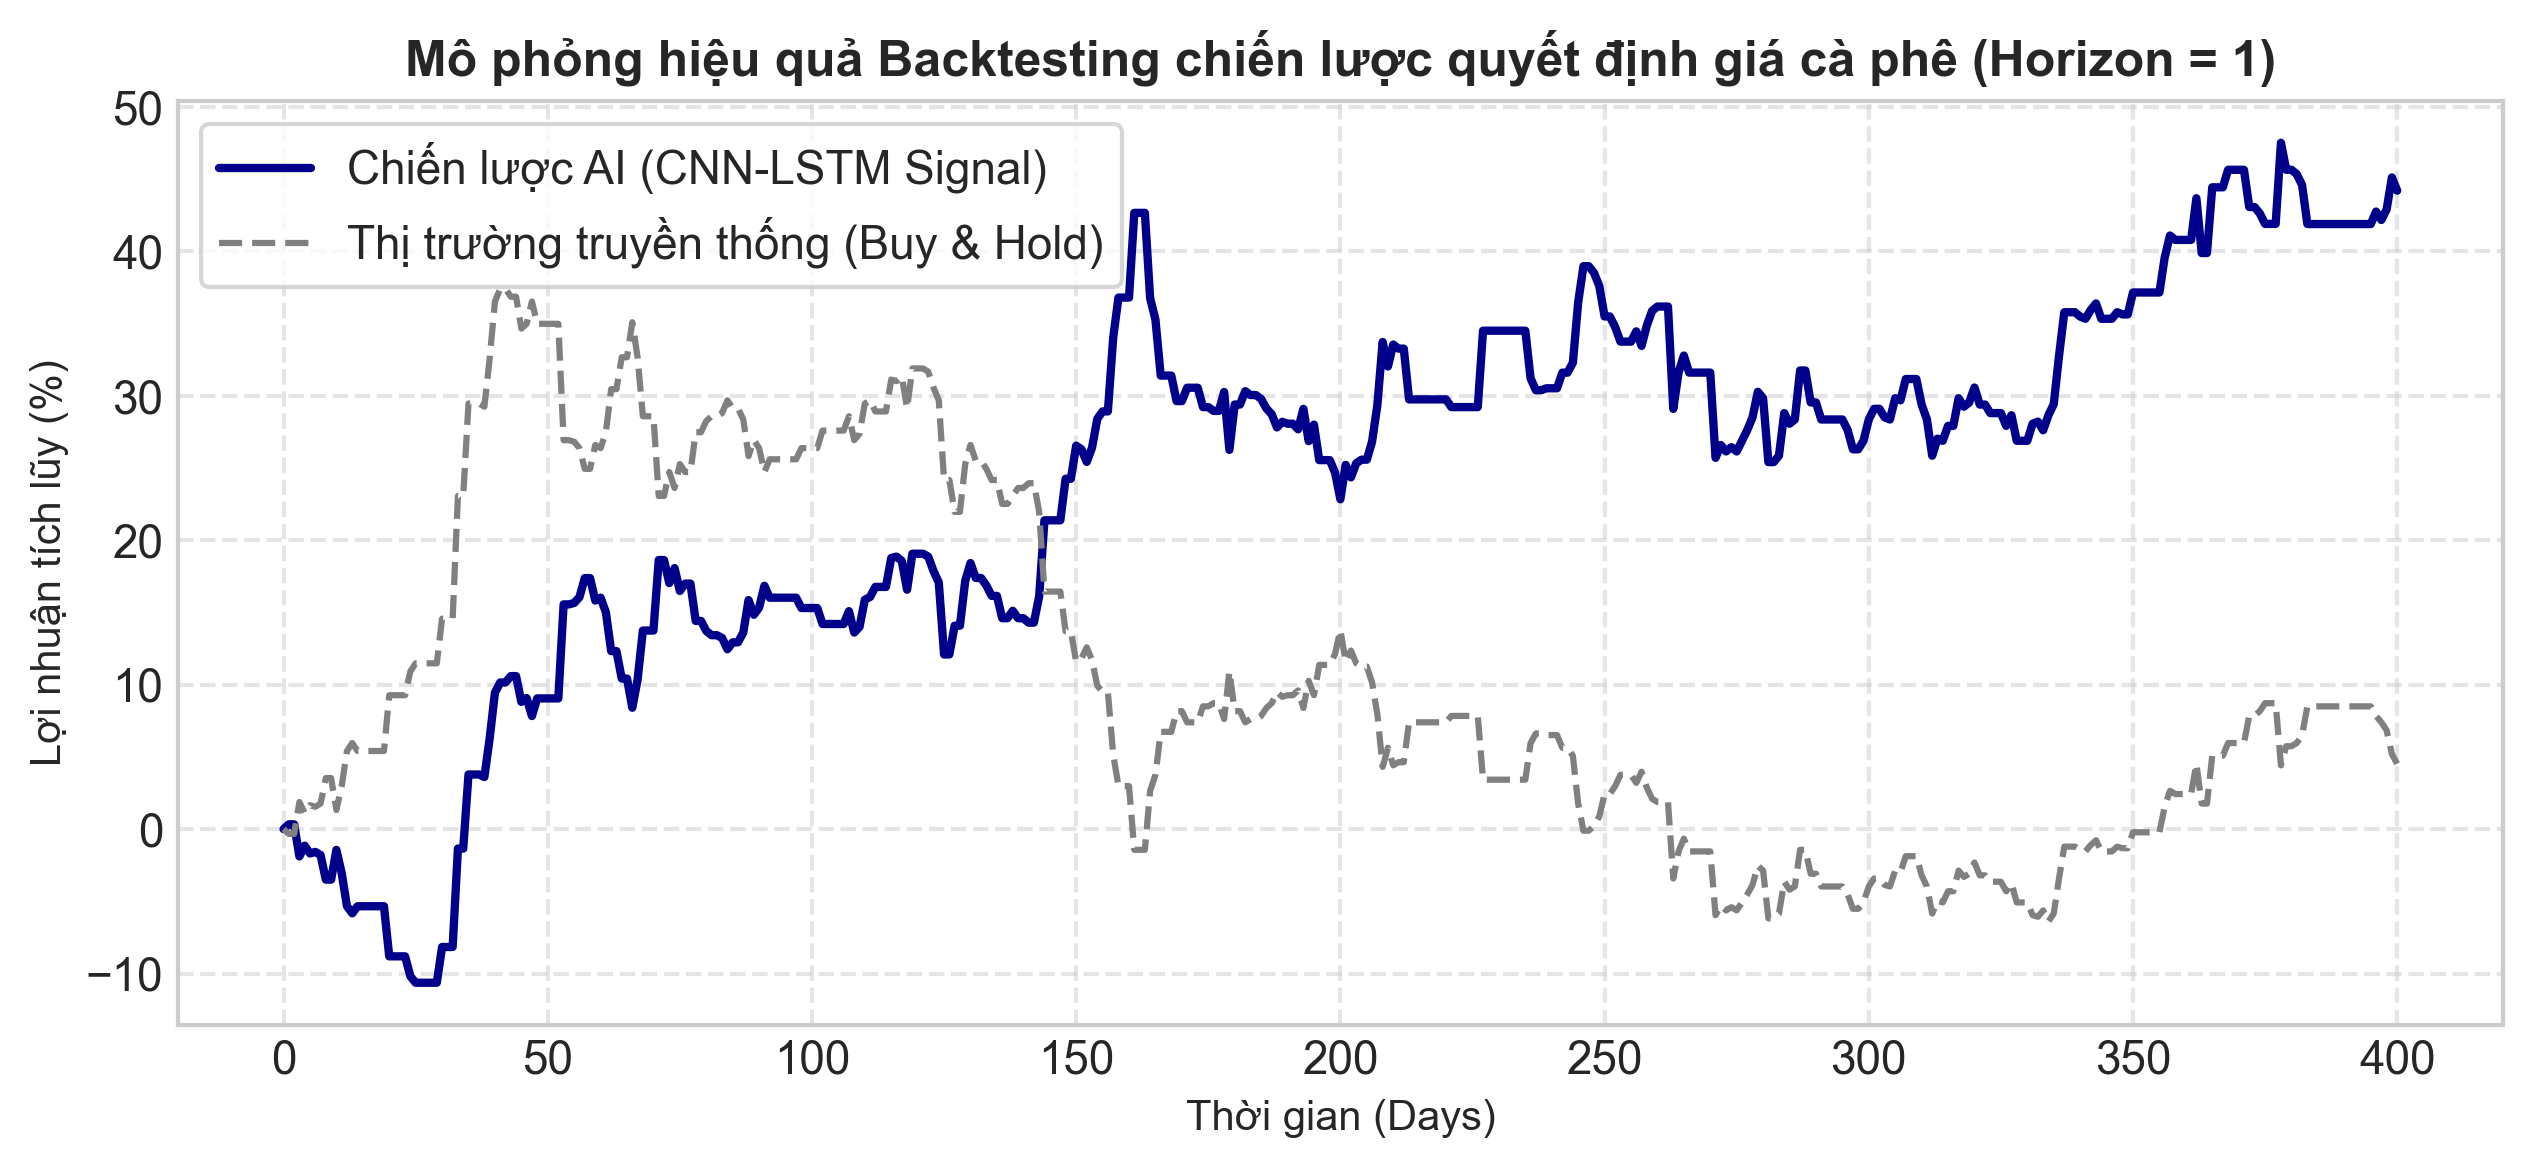

In [67]:
def evaluate_trading_strategy_horizon1(actual_prices, predicted_prices, base_prices):
    """
    Backtesting cho mô hình dự báo 1 ngày tới (Horizon = 1):
    - Tín hiệu: Nếu giá dự báo ngày mai > giá hiện tại -> Mua/Giữ (1), ngược lại Bán (-1).
    """
    strategy_returns = []
    market_returns = []
    
    # actual_prices và predicted_prices lúc này là mảng 1 chiều (hoặc shape (N, 1))
    actual_flat = actual_prices.flatten()
    pred_flat = predicted_prices.flatten()
    
    for i in range(1, len(actual_flat)):
        current_price = actual_flat[i - 1]
        future_actual_price = actual_flat[i]
        future_pred_price = pred_flat[i]
        
        # Tín hiệu giao dịch dựa trên dự báo tăng/giảm so với ngày hiện tại
        signal = 1 if future_pred_price > current_price else -1
        
        # Lợi nhuận thị trường thực tế
        market_ret = (future_actual_price - current_price) / current_price
        
        # Lợi nhuận chiến lược theo tín hiệu AI
        strat_ret = signal * market_ret
        
        strategy_returns.append(strat_ret)
        market_returns.append(market_ret)
        
    cum_strategy = np.cumprod(1 + np.array(strategy_returns)) - 1
    cum_market = np.cumprod(1 + np.array(market_returns)) - 1
    
    print(f"Lợi nhuận tích lũy chiến lược AI (CNN-LSTM) : {cum_strategy[-1]*100:.2f}%")
    print(f"Lợi nhuận tích lũy thị trường (Buy & Hold)     : {cum_market[-1]*100:.2f}%")
    
    # Trực quan hóa biểu đồ Backtesting
    plt.figure(figsize=(10, 4))
    plt.plot(cum_strategy * 100, label='Chiến lược AI (CNN-LSTM Signal)', color='darkblue', linewidth=2)
    plt.plot(cum_market * 100, label='Thị trường truyền thống (Buy & Hold)', color='gray', linestyle='--', linewidth=1.5)
    plt.title('Mô phỏng hiệu quả Backtesting chiến lược quyết định giá cà phê (Horizon = 1)', fontsize=12, fontweight='bold')
    plt.xlabel('Thời gian (Days)', fontsize=10)
    plt.ylabel('Lợi nhuận tích lũy (%)', fontsize=10)
    plt.legend(frameon=True)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

# Thực thi lại hàm backtesting với giá thực tế và giá dự báo
evaluate_trading_strategy_horizon1(actual_prices_arr, predicted_prices_arr, raw_prices[test_split : test_split + len(actual_prices_arr)])